# 04 · Bollinger Bands

| | |
|---|---|
| **Question** | Can a simple statistical band around a stock price tell you when to buy or sell? |
| **Data** | Yahoo Finance (via `yfinance`). Saved copy: `data/stock_data.csv` |
| **Skills** | Rolling statistics, plotting with matplotlib, interactive widgets, testing a trading rule |
| **Runs in** | Colab: yes. JupyterLite: yes (uses the saved data) |

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ericvd-ucb/Colombia-26-NB/blob/main/notebooks/04_bollinger_bands.ipynb) [![Open in JupyterLite](https://jupyterlite.rtfd.io/en/latest/_static/badge.svg)](https://ericvd-ucb.github.io/Colombia-26-NB/lab/index.html?path=notebooks/04_bollinger_bands.ipynb)

*Eric Van Dusen, UC Berkeley College of Computing, Data Science, and Society. Prepared for students in Colombia, October 2026.*

In [ ]:
# Setup: run this cell first. It works in Google Colab, JupyterLite, or on your own computer.
import os, sys
IN_COLAB = "google.colab" in sys.modules
IN_JUPYTERLITE = sys.platform == "emscripten"

# Saved data lives in the repo's data/ folder; in Colab we download it from GitHub when needed
DATA_URL = "https://raw.githubusercontent.com/ericvd-ucb/Colombia-26-NB/main/data/"
DATA_DIR = "../data" if os.path.isdir("../data") else "data"
os.makedirs(DATA_DIR, exist_ok=True)

def data_path(filename):
    """Local path to a file from the repo's data/ folder, downloading it first if it isn't here."""
    local = os.path.join(DATA_DIR, filename)
    if not os.path.exists(local):
        import urllib.request
        urllib.request.urlretrieve(DATA_URL + filename, local)
    return local

if IN_JUPYTERLITE:
    %pip install -q ipywidgets

# Finance and Graphics Demo
## Calculate Bollinger Bands
## Graph with MatplotLib 
## Use a widget to make it interactive
## Trading Strategy!



In [1]:

import pandas as pd
import matplotlib.pyplot as plt 

import ipywidgets as widgets
from IPython.display import display
%matplotlib inline

In [2]:
try:
    import yfinance as yf
except ImportError:
    yf = None  # not available here (for example in JupyterLite); we will use the saved data

## Let's download a stocks Dataset


In [3]:
# Define the tickers for multiple stocks
tickers = ["AAPL", "GOOG", "AMZN", "META", "NVDA", "MSFT"]

# Download historical data, or fall back to the saved copy in data/stock_data.csv
try:
    stock_data = yf.download(tickers, start="2019-01-01", end="2026-10-10", group_by="ticker")
    if stock_data.empty:
        raise ValueError("no data returned")
    stock_data.to_csv(os.path.join(DATA_DIR, "stock_data.csv"))
except Exception as err:
    print("Live download unavailable, using the saved data:", err)
    stock_data = pd.read_csv(data_path("stock_data.csv"), header=[0, 1], index_col=0, parse_dates=True)

# Display the first few rows
stock_data

/var/folders/wx/mgl11c114vv7vpz1f_b7szwr0000gn/T/ipykernel_29558/560152745.py:5: FutureWarning: YF.download() has changed argument auto_adjust default to True
  stock_data = yf.download(tickers, start="2019-01-01", end="2026-10-10", group_by="ticker")
[*********************100%***********************]  6 of 6 completed


Ticker            GOOG                                                \
Price             Open        High         Low       Close    Volume   
Date                                                                   
2019-01-02   50.351589   52.122319   50.308993   51.801853  30652000   
2019-01-03   51.561626   52.353129   50.227759   50.326328  36822000   
2019-01-04   51.145073   53.039627   50.888897   53.033188  41878000   
2019-01-07   53.072313   53.196141   52.243165   52.918270  39638000   
2019-01-08   53.300659   53.719195   52.528969   53.309078  35298000   
...                ...         ...         ...         ...       ...   
2026-10-05  339.209991  344.989990  339.149994  343.829987  13982200   
2026-10-06  344.640015  345.670013  341.700012  344.589996  13177400   
2026-10-07  343.679993  347.609985  340.279999  347.369995  11344700   
2026-10-08  349.644989  353.529999  343.510010  344.859985  13987000   
2026-10-09  348.000000  351.059998  346.880005  347.859985  11142900   

Ticker            NVDA                                                 ...  \
Price             Open        High         Low       Close     Volume  ...   
Date                                                                   ...   
2019-01-02    3.231266    3.425182    3.216673    3.369283  508752000  ...   
2019-01-03    3.309178    3.343064    3.158300    3.165720  705552000  ...   
2019-01-04    3.238686    3.406630    3.208015    3.368540  585620000  ...   
2019-01-07    3.425676    3.583727    3.374476    3.546873  709160000  ...   
2019-01-08    3.628249    3.630475    3.386102    3.458573  786016000  ...   
...                ...         ...         ...         ...        ...  ...   
2026-10-05  236.089996  240.100006  235.149994  238.899994  127171500  ...   
2026-10-06  242.100006  243.369995  238.929993  239.240005  101701900  ...   
2026-10-07  237.690002  239.080002  236.380005  237.470001   81772400  ...   
2026-10-08  234.919998  237.070007  229.850006  230.479996  118697400  ...   
2026-10-09  233.839996  233.919998  229.110001  229.279999   84645600  ...   

Ticker            META                                                \
Price             Open        High         Low       Close    Volume   
Date                                                                   
2019-01-02  127.766302  136.205463  127.340373  134.392822  28146200   
2019-01-03  133.412246  135.868715  129.876106  130.490234  22717900   
2019-01-04  132.738672  136.690825  132.481144  136.641296  29002100   
2019-01-07  136.255000  137.552569  134.620659  136.740356  20089300   
2019-01-08  138.562902  141.782070  138.216216  141.177856  26263800   
...                ...         ...         ...         ...       ...   
2026-10-05  727.710022  746.700012  727.119995  741.900024  15215300   
2026-10-06  746.729980  747.599976  736.690002  738.880005  12563100   
2026-10-07  738.289978  738.289978  720.150024  721.309998  13231600   
2026-10-08  724.539978  724.950012  711.679993  720.890015  16041100   
2026-10-09  726.510010  728.070007  716.200012  718.669983  12619900   

Ticker            AAPL                                                 
Price             Open        High         Low       Close     Volume  
Date                                                                   
2019-01-02   36.718621   37.657390   36.562159   37.436920  148158800  
2019-01-03   34.132264   34.544754   33.662881   33.707924  365248800  
2019-01-04   34.262654   35.215647   34.089599   35.146896  234428400  
2019-01-07   35.251200   35.282019   34.587424   35.068661  219111200  
2019-01-08   35.455085   35.990849   35.208542   35.737190  164101200  
...                ...         ...         ...         ...        ...  
2026-10-05  332.820007  336.209991  331.649994  332.890015   34400900  
2026-10-06  332.279999  334.380005  330.619995  333.630005   30449000  
2026-10-07  336.959991  338.670013  332.779999  336.670013   34147900  
2026-10-08  336.820007  3

In [4]:
# Extract AAPL data
ap_prices = stock_data['AAPL'].copy()
ap_prices

Price,Open,High,Low,Close,Volume
Date,,,,,
2019-01-02,36.718621,37.657390,36.562159,37.436920,148158800
2019-01-03,34.132264,34.544754,33.662881,33.707924,365248800
2019-01-04,34.262654,35.215647,34.089599,35.146896,234428400
2019-01-07,35.251200,35.282019,34.587424,35.068661,219111200
2019-01-08,35.455085,35.990849,35.208542,35.737190,164101200
...,...,...,...,...,...
2026-10-05,332.820007,336.209991,331.649994,332.890015,34400900
2026-10-06,332.279999,334.380005,330.619995,333.630005,30449000
2026-10-07,336.959991,338.670013,332.779999,336.670013,34147900


# Bollinger Bands Explained

Bollinger Bands are a **technical analysis tool** used to measure market volatility and identify overbought or oversold conditions. They consist of three lines:

1. **Middle Band** – A simple moving average (SMA), typically a **20-day SMA**.
2. **Upper Band** – The SMA plus **2 standard deviations**.
3. **Lower Band** – The SMA minus **2 standard deviations**.

Since standard deviation measures volatility, the bands expand when the market is volatile and contract when the market is stable.

---

## **Formula for Bollinger Bands**
Given a time period \( N \) (typically 20 days):

- **Middle Band (SMA)**:  
  $$ \text{SMA} = \frac{1}{N} \sum_{i=1}^{N} P_i $$  
  where \( P_i \) is the price at day \( i \).

- **Upper Band**:  
  $$ \text{Upper Band} = \text{SMA} + (k \times \sigma) $$

- **Lower Band**:  
  $$ \text{Lower Band} = \text{SMA} - (k \times \sigma) $$
where:
-  $\sigma $ is the standard deviation of prices over $ N $ days.
- $k$ is typically **2**, meaning bands are **2 standard deviations** from the SMA.

---

## **How to Interpret Bollinger Bands**
1. **Price Near the Upper Band → Overbought**
   - If the price touches or moves above the upper band, the asset **may be overbought**, signaling a possible reversal downward.

2. **Price Near the Lower Band → Oversold**
   - If the price touches or moves below the lower band, the asset **may be oversold**, signaling a possible upward reversal.

3. **Bollinger Band Squeeze → Low Volatility**
   - When bands contract, it signals **low volatility** and often precedes a breakout in either direction.

4. **Bollinger Band Expansion → High Volatility**
   - When bands widen, volatility is increasing. This often happens after a strong move in price.

---


## Calculate the new Bollinger Bands columns
`Pandas` has a `.rolling` argument that we can pass in

In [5]:
window = 20  

In [6]:
ap_prices['SMA'] = ap_prices['Close'].rolling(window).mean()  # Simple Moving Average
ap_prices['StdDev'] = ap_prices['Close'].rolling(window).std()  # Standard Deviation
ap_prices['Upper'] = ap_prices['SMA'] + (2 * ap_prices['StdDev'])  # Upper Band
ap_prices['Lower'] = ap_prices['SMA'] - (2 * ap_prices['StdDev'])  # Lower Band

In [7]:
ap_prices = ap_prices.dropna()
ap_prices

Price,Open,High,Low,Close,Volume,SMA,StdDev,Upper,Lower
Date,,,,,,,,,
2019-01-30,38.700458,39.387938,37.984529,39.174583,244439200,36.401547,1.104490,38.610528,34.192567
2019-01-31,39.378464,40.063575,39.011017,39.456696,162958400,36.502536,1.282186,39.066909,33.938163
2019-02-01,39.579959,40.058823,39.335781,39.475651,130672400,36.790923,1.269112,39.329147,34.252699
2019-02-04,39.686643,40.694158,39.655823,40.596962,125982000,37.063426,1.467189,39.997803,34.129048
2019-02-05,40.978640,41.504920,40.857740,41.291561,144406400,37.374571,1.667996,40.710564,34.038578
...,...,...,...,...,...,...,...,...,...
2026-10-05,332.820007,336.209991,331.649994,332.890015,34400900,332.541000,6.809208,346.159417,318.922584
2026-10-06,332.279999,334.380005,330.619995,333.630005,30449000,333.411501,5.622308,344.656116,322.166885
2026-10-07,336.959991,338.670013,332.779999,336.670013,34147900,334.478001,3.712615,341.903231,327.052772


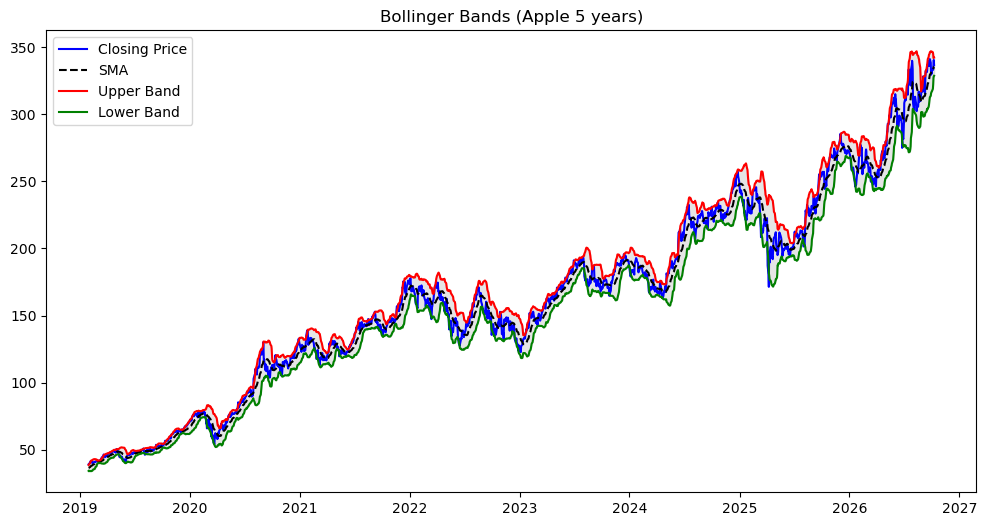

In [8]:
plt.figure(figsize=(12, 6))
plt.plot(ap_prices.index, ap_prices['Close'], label="Closing Price", color='blue')
plt.plot(ap_prices.index, ap_prices['SMA'], label="SMA", color='black', linestyle="dashed")
plt.plot(ap_prices.index, ap_prices['Upper'], label="Upper Band", color='red')
plt.plot(ap_prices.index, ap_prices['Lower'], label="Lower Band", color='green')
plt.fill_between(ap_prices.index, ap_prices['Upper'], ap_prices['Lower'], color='gray', alpha=0.2)
plt.title("Bollinger Bands (Apple 5 years)")
plt.legend()
plt.show()

In [9]:
# Filter the data to only include the last year
last_year = ap_prices.loc[ap_prices.index >= ap_prices.index.max() - pd.DateOffset(years=1)].copy()


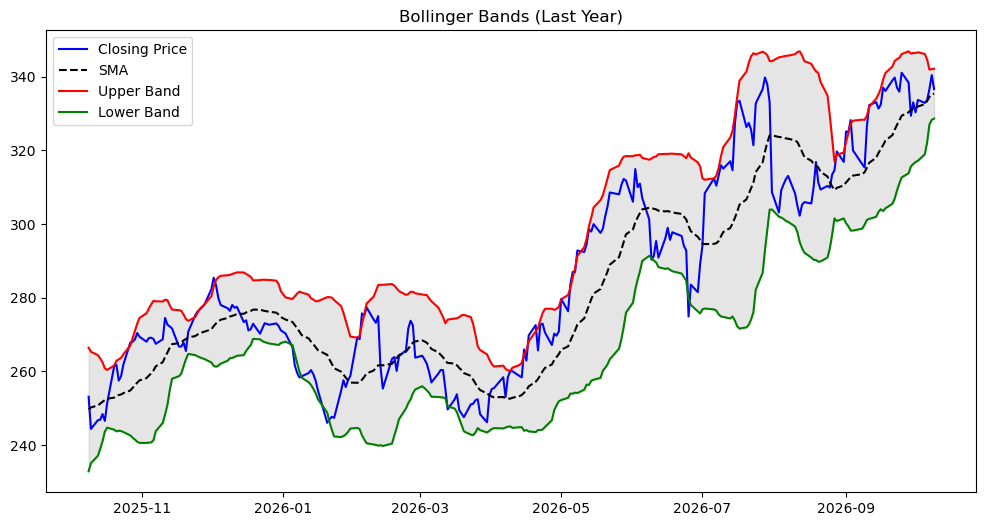

In [10]:
# Plot Bollinger Bands for the last year
plt.figure(figsize=(12, 6))
plt.plot(last_year.index, last_year['Close'], label="Closing Price", color='blue')
plt.plot(last_year.index, last_year['SMA'], label="SMA", color='black', linestyle="dashed")
plt.plot(last_year.index, last_year['Upper'], label="Upper Band", color='red')
plt.plot(last_year.index, last_year['Lower'], label="Lower Band", color='green')

# Fill the area between the upper and lower bands
plt.fill_between(last_year.index, last_year['Upper'].values, last_year['Lower'].values, color='gray', alpha=0.2)

plt.title("Bollinger Bands (Last Year)")
plt.legend()
plt.show()

## Identify overbought conditions where the closing price is above the upper Bollinger Band

In [11]:
overbought = last_year[last_year['Close'] > last_year['Upper']]

overbought

# add oversold
oversold = last_year[last_year['Close'] < last_year['Lower']]

oversold

Price,Open,High,Low,Close,Volume,SMA,StdDev,Upper,Lower
Date,,,,,,,,,
2026-01-05,269.905376,270.773009,265.417591,266.534546,45647200,273.399318,3.117301,279.633919,267.164717
2026-01-06,266.275185,266.823679,261.408427,261.647766,52352100,272.580545,3.892938,280.366421,264.794669
2026-01-07,262.485556,262.964234,259.104744,259.623322,48309800,271.704929,4.700229,281.105387,262.304470
2026-01-08,256.322317,258.586174,255.005908,258.336853,50419300,270.800394,5.427947,281.656288,259.944500
2026-01-20,252.043949,254.098355,242.759224,246.030319,80267500,264.479105,7.835662,280.150430,248.807780
2026-03-13,255.024891,255.873368,249.075516,249.674438,36930000,262.281444,5.889191,274.059825,250.503062
2026-06-09,300.021248,300.490844,287.532019,290.299622,70108800,304.295564,6.746922,317.789409,290.801720
2026-06-25,287.152347,288.551135,273.514115,274.912903,107013700,299.466728,9.878966,319.224659,279.708797


### Plot Bollinger Bands with overbought conditions highlighted


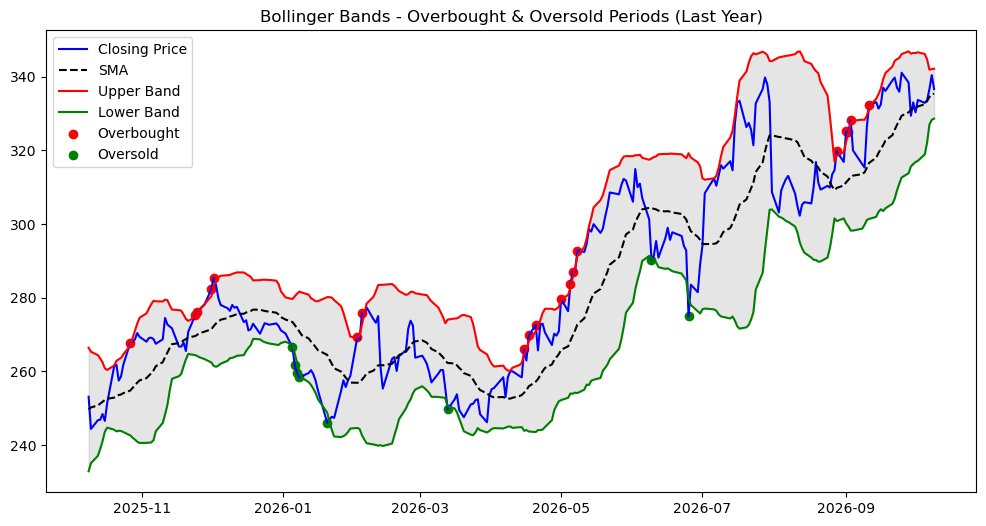

In [12]:
plt.figure(figsize=(12, 6))
plt.plot(last_year.index, last_year['Close'], label="Closing Price", color='blue')
plt.plot(last_year.index, last_year['SMA'], label="SMA", color='black', linestyle="dashed")
plt.plot(last_year.index, last_year['Upper'], label="Upper Band", color='red')
plt.plot(last_year.index, last_year['Lower'], label="Lower Band", color='green')

# Fill the Bollinger Bands range
plt.fill_between(last_year.index, last_year['Upper'].values, last_year['Lower'].values, color='gray', alpha=0.2)

# Highlight overbought points
plt.scatter(overbought.index, overbought['Close'], color='red', label="Overbought", marker='o')

# Highlight oversold points
plt.scatter(oversold.index, oversold['Close'], color='green', label="Oversold", marker='o')

plt.title("Bollinger Bands - Overbought & Oversold Periods (Last Year)")
plt.legend()
plt.show()

## Lets build some widgets!

In [13]:
tickers

['AAPL', 'GOOG', 'AMZN', 'META', 'NVDA', 'MSFT']

In [ ]:
# Create dropdown for stock selection
stock_picker = widgets.Dropdown(
    options=tickers,
    value="AAPL",
    description="Stock:"
)

# Create slider for selecting the time window in years
time_window = widgets.IntSlider(
    value=1,  # Default to 1 year
    min=1,
    max=5,
    step=1,
    description="Years:"
)



# Create slider for MA window size
ma_window = widgets.IntSlider(
    value=20,  # Default to 20 days
    min=5,
    max=50,
    step=5,
    description="MA Window:"
)

In [15]:
# Display widgets
display(stock_picker, time_window, ma_window)

Dropdown(description='Stock:', options=('AAPL', 'GOOG', 'AMZN', 'META', 'NVDA', 'MSFT'), value='AAPL')

IntSlider(value=1, description='Years:', max=5, min=1)

IntSlider(value=20, description='MA Window:', max=50, min=5, step=5)

## Lets make the Graph again but lets let it update with the widgets

- put the whole graph in a function 
- fuction takes 3 arguments which are the widgets
- plot it and have it update as widgets change


In [16]:
# Function to compute and plot Bollinger Bands
def plot_bollinger_bands(stock, years, window=20):
    # Extract only the selected stock's data
    df = stock_data[stock].copy()
    
    # Get the last date in the dataset and compute the start date
    end_date = df.index.max()
    start_date = end_date - pd.DateOffset(years=years)
    
    # Filter data based on the selected time window
    df = df.loc[start_date:end_date]

    # Compute Bollinger Bands
    df['SMA'] = df['Close'].rolling(window).mean()
    df['StdDev'] = df['Close'].rolling(window).std()
    df['Upper'] = df['SMA'] + (2 * df['StdDev'])
    df['Lower'] = df['SMA'] - (2 * df['StdDev'])

    # Drop NaN values
    df = df.dropna()

    # Plot Bollinger Bands
    plt.figure(figsize=(12, 6))
    plt.plot(df.index, df['Close'], label="Closing Price", color='blue')
    plt.plot(df.index, df['SMA'], label="SMA", color='black', linestyle="dashed")
    plt.plot(df.index, df['Upper'], label="Upper Band", color='red')
    plt.plot(df.index, df['Lower'], label="Lower Band", color='green')
    plt.fill_between(df.index, df['Upper'], df['Lower'], color='gray', alpha=0.2)

    plt.title(f"Bollinger Bands for {stock} ({years} Year(s), MA={window})")
    plt.legend()
    plt.show()



In [ ]:
# Create an interactive widget with output
output = widgets.Output()

# Function to update the output widget
def update_plot(stock, years, window):
    with output:
        output.clear_output(wait=True)
        plot_bollinger_bands(stock, years, window)

# Create interactive widgets
interactive_plot = widgets.interactive(update_plot, stock=stock_picker, years=time_window, window=ma_window)

# Display widgets and output
display(stock_picker, time_window, ma_window, output)

# Call the function once to display initial plot
update_plot(stock_picker.value, time_window.value, ma_window.value)

Dropdown(description='Stock:', options=('AAPL', 'GOOG', 'AMZN', 'META', 'NVDA', 'MSFT'), value='AAPL')

IntSlider(value=1, description='Years:', max=5, min=1)

IntSlider(value=20, description='MA Window:', max=50, min=5, step=5)

Output()

## Can we make a trading rule 
- buy when oversold for 2 days 
- sell when overbought 2 days

## When would trades get made?

In [24]:
# Create signals for oversold and overbought conditions
last_year['oversold_signal'] = (last_year['Close'] < last_year['Lower']).astype(int)
last_year['overbought_signal'] = (last_year['Close'] > last_year['Upper']).astype(int)

# Check for 2 consecutive days of oversold/overbought
# Rolling sum of 2 periods - if it equals 2, then we had 2 consecutive days
last_year['oversold_2days'] = last_year['oversold_signal'].rolling(2).sum() == 2
last_year['overbought_2days'] = last_year['overbought_signal'].rolling(2).sum() == 2

last_year[['Close', 'Lower', 'Upper', 'oversold_signal', 'overbought_signal', 'oversold_2days', 'overbought_2days']].tail(20)

Price,Close,Lower,Upper,oversold_signal,overbought_signal,oversold_2days,overbought_2days
Date,,,,,,,
2026-09-14,333.079987,301.946480,334.020515,0,0,False,False
2026-09-15,331.339996,303.288920,335.253075,0,0,False,False
2026-09-16,332.410004,304.003409,336.776587,0,0,False,False
2026-09-17,337.000000,303.519676,339.277322,0,0,False,False
2026-09-18,336.130005,304.272068,341.007931,0,0,False,False
2026-09-21,338.980011,305.489131,342.753869,0,0,False,False
2026-09-22,339.750000,306.897180,344.286819,0,0,False,False
2026-09-23,337.019989,309.132025,344.763974,0,0,False,False
2026-09-24,335.920013,311.022043,345.120956,0,0,False,False


In [25]:
# Generate trading signals
# Buy signal: When we hit 2 consecutive oversold days (day 2 of the signal)
# Sell signal: When we hit 2 consecutive overbought days (day 2 of the signal)

# Shift to ensure we're only counting the transition into the 2-day period
last_year['buy_signal'] = last_year['oversold_2days'] & ~last_year['oversold_2days'].shift(1, fill_value=False)
last_year['sell_signal'] = last_year['overbought_2days'] & ~last_year['overbought_2days'].shift(1, fill_value=False)

# Get the dates when trades would be made
buy_dates = last_year[last_year['buy_signal']]
sell_dates = last_year[last_year['sell_signal']]

print(f"Number of BUY signals: {len(buy_dates)}")
print(f"Number of SELL signals: {len(sell_dates)}")
print("\nBuy signals:")
print(buy_dates[['Close', 'Lower', 'Upper']])
print("\nSell signals:")
print(sell_dates[['Close', 'Lower', 'Upper']])

Number of BUY signals: 1
Number of SELL signals: 5

Buy signals:
Price            Close       Lower       Upper
Date                                          
2026-01-06  261.647766  264.794669  280.366421

Sell signals:
Price            Close       Lower       Upper
Date                                          
2025-11-25  276.218140  264.099383  275.875748
2025-12-02  285.413116  261.483278  283.100947
2026-04-20  272.563568  243.520452  270.839644
2026-05-06  286.997864  253.941009  285.540256
2026-09-02  324.959991  299.361598  324.620482


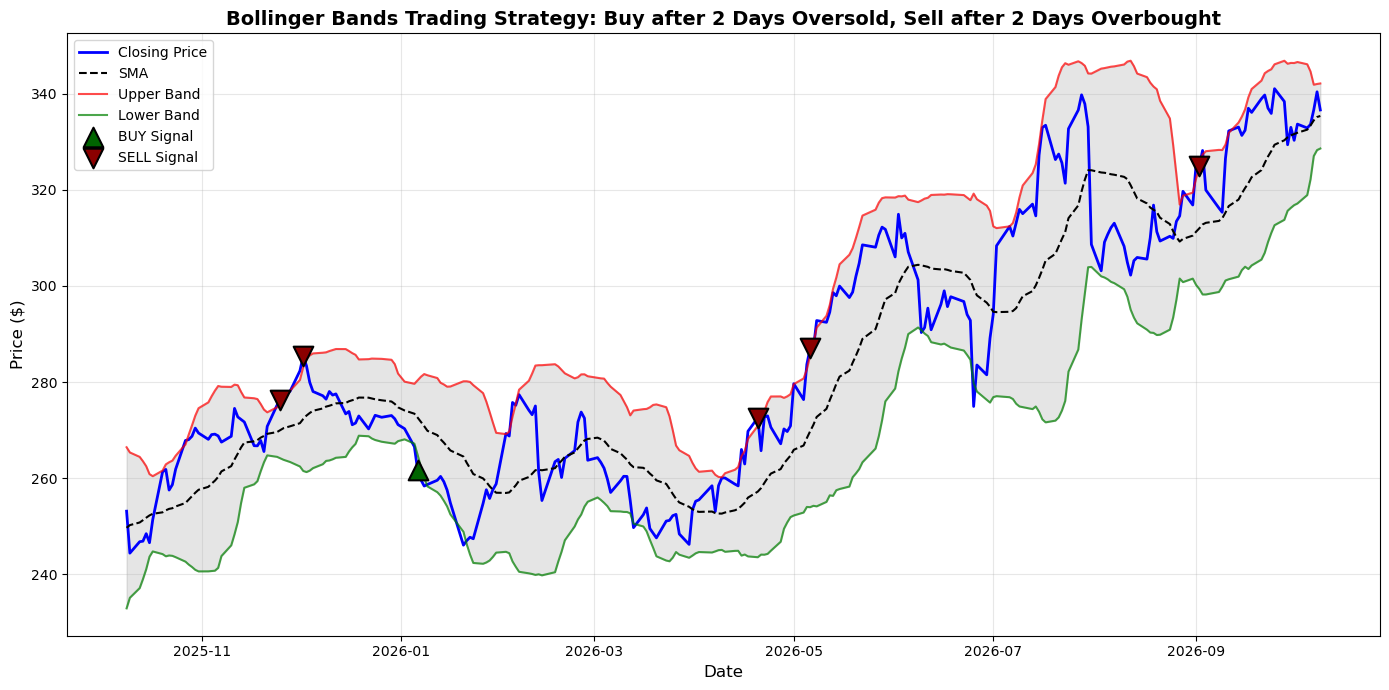

In [26]:
# Visualize the trading signals on the Bollinger Bands chart
plt.figure(figsize=(14, 7))

# Plot Bollinger Bands
plt.plot(last_year.index, last_year['Close'], label="Closing Price", color='blue', linewidth=2)
plt.plot(last_year.index, last_year['SMA'], label="SMA", color='black', linestyle="dashed")
plt.plot(last_year.index, last_year['Upper'], label="Upper Band", color='red', alpha=0.7)
plt.plot(last_year.index, last_year['Lower'], label="Lower Band", color='green', alpha=0.7)
plt.fill_between(last_year.index, last_year['Upper'].values, last_year['Lower'].values, color='gray', alpha=0.2)

# Mark BUY signals (green triangles pointing up)
if len(buy_dates) > 0:
    plt.scatter(buy_dates.index, buy_dates['Close'], color='darkgreen', marker='^', 
                s=200, label="BUY Signal", zorder=5, edgecolors='black', linewidth=1.5)

# Mark SELL signals (red triangles pointing down)
if len(sell_dates) > 0:
    plt.scatter(sell_dates.index, sell_dates['Close'], color='darkred', marker='v', 
                s=200, label="SELL Signal", zorder=5, edgecolors='black', linewidth=1.5)

plt.title("Bollinger Bands Trading Strategy: Buy after 2 Days Oversold, Sell after 2 Days Overbought", 
          fontsize=14, fontweight='bold')
plt.xlabel("Date", fontsize=12)
plt.ylabel("Price ($)", fontsize=12)
plt.legend(loc='best')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### Trading Strategy Performance

Let's calculate a simple returns analysis:
- Assume we buy at the close price on a buy signal
- Assume we sell at the close price on a sell signal
- Calculate the return for each buy-sell pair

In [21]:
# Simple trading performance calculation
# Match each buy with the next sell signal

if len(buy_dates) > 0 and len(sell_dates) > 0:
    trades = []
    
    for buy_date in buy_dates.index:
        # Find the next sell signal after this buy
        future_sells = sell_dates[sell_dates.index > buy_date]
        
        if len(future_sells) > 0:
            sell_date = future_sells.index[0]
            buy_price = buy_dates.loc[buy_date, 'Close']
            sell_price = sell_dates.loc[sell_date, 'Close']
            
            profit = sell_price - buy_price
            return_pct = (profit / buy_price) * 100
            
            trades.append({
                'Buy Date': buy_date,
                'Buy Price': buy_price,
                'Sell Date': sell_date,
                'Sell Price': sell_price,
                'Profit ($)': profit,
                'Return (%)': return_pct
            })
    
    trades_df = pd.DataFrame(trades)
    print(f"\nTotal number of completed trades: {len(trades_df)}")
    print(f"Average return per trade: {trades_df['Return (%)'].mean():.2f}%")
    print(f"Total profit: ${trades_df['Profit ($)'].sum():.2f}\n")
    print(trades_df)
else:
    print("Not enough buy/sell signals to calculate performance")


Total number of completed trades: 1
Average return per trade: 4.17%
Total profit: $10.92

    Buy Date   Buy Price  Sell Date  Sell Price  Profit ($)  Return (%)
0 2026-01-06  261.647766 2026-04-20  272.563568   10.915802    4.171945


### Compare to Buy-and-Hold Strategy

Let's compare the trading strategy to simply buying at the beginning and holding until the end.

In [22]:
# Calculate Buy-and-Hold performance for the same period
buy_hold_start_price = last_year['Close'].iloc[0]
buy_hold_end_price = last_year['Close'].iloc[-1]
buy_hold_profit = buy_hold_end_price - buy_hold_start_price
buy_hold_return = (buy_hold_profit / buy_hold_start_price) * 100

print("=" * 60)
print("PERFORMANCE COMPARISON")
print("=" * 60)
print(f"\n📊 BUY-AND-HOLD STRATEGY:")
print(f"   Start Date: {last_year.index[0].strftime('%Y-%m-%d')}")
print(f"   End Date: {last_year.index[-1].strftime('%Y-%m-%d')}")
print(f"   Buy Price: ${buy_hold_start_price:.2f}")
print(f"   End Price: ${buy_hold_end_price:.2f}")
print(f"   Total Return: {buy_hold_return:.2f}%")
print(f"   Total Profit: ${buy_hold_profit:.2f}")

if len(buy_dates) > 0 and len(sell_dates) > 0 and len(trades_df) > 0:
    trading_total_return = trades_df['Return (%)'].sum()
    trading_total_profit = trades_df['Profit ($)'].sum()
    
    print(f"\n📈 BOLLINGER TRADING STRATEGY:")
    print(f"   Number of Trades: {len(trades_df)}")
    print(f"   Average Return per Trade: {trades_df['Return (%)'].mean():.2f}%")
    print(f"   Total Return: {trading_total_return:.2f}%")
    print(f"   Total Profit: ${trading_total_profit:.2f}")
    
    print(f"\n{'='*60}")
    print("COMPARISON:")
    print(f"{'='*60}")
    
    if trading_total_return > buy_hold_return:
        outperformance = trading_total_return - buy_hold_return
        print(f"✅ Trading Strategy OUTPERFORMED by {outperformance:.2f}%")
    else:
        underperformance = buy_hold_return - trading_total_return
        print(f"❌ Trading Strategy UNDERPERFORMED by {underperformance:.2f}%")
    
    profit_diff = trading_total_profit - buy_hold_profit
    if profit_diff > 0:
        print(f"   Extra profit: ${profit_diff:.2f}")
    else:
        print(f"   Less profit: ${abs(profit_diff):.2f}")
else:
    print("\n⚠️  Not enough trading signals to compare strategies")

PERFORMANCE COMPARISON

📊 BUY-AND-HOLD STRATEGY:
   Start Date: 2025-10-09
   End Date: 2026-10-09
   Buy Price: $253.11
   End Price: $336.64
   Total Return: 33.00%
   Total Profit: $83.53

📈 BOLLINGER TRADING STRATEGY:
   Number of Trades: 1
   Average Return per Trade: 4.17%
   Total Return: 4.17%
   Total Profit: $10.92

COMPARISON:
❌ Trading Strategy UNDERPERFORMED by 28.83%
   Less profit: $72.62


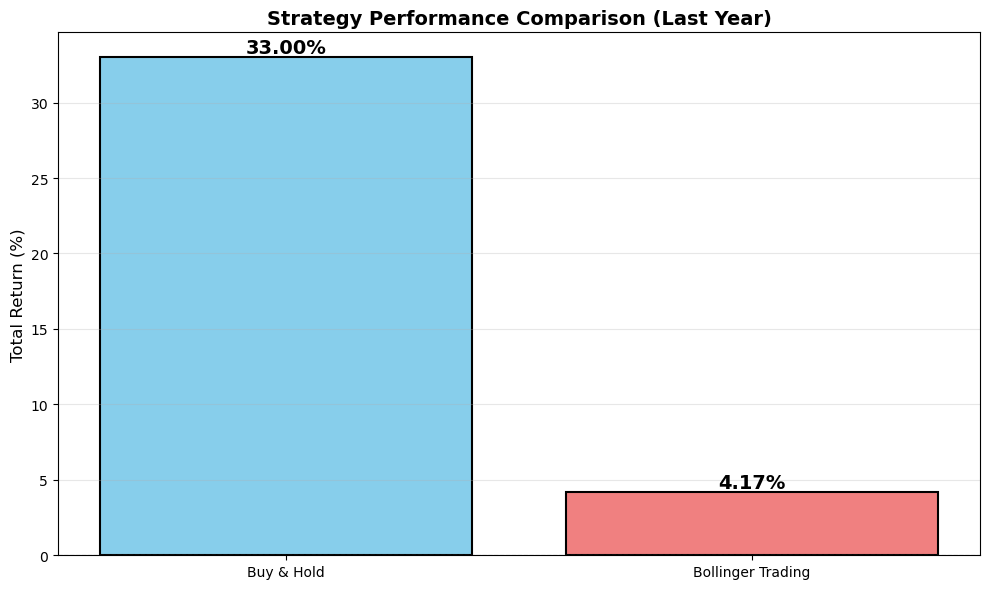

In [23]:
# Visualize the comparison
if len(buy_dates) > 0 and len(sell_dates) > 0 and len(trades_df) > 0:
    strategies = ['Buy & Hold', 'Bollinger Trading']
    returns = [buy_hold_return, trades_df['Return (%)'].sum()]
    colors = ['skyblue', 'lightcoral']
    
    # Determine which is better and adjust colors
    if returns[1] > returns[0]:
        colors[1] = 'lightgreen'
    
    fig, ax = plt.subplots(figsize=(10, 6))
    bars = ax.bar(strategies, returns, color=colors, edgecolor='black', linewidth=1.5)
    
    # Add value labels on bars
    for bar, ret in zip(bars, returns):
        height = bar.get_height()
        ax.text(bar.get_x() + bar.get_width()/2., height,
                f'{ret:.2f}%',
                ha='center', va='bottom', fontsize=14, fontweight='bold')
    
    ax.set_ylabel('Total Return (%)', fontsize=12)
    ax.set_title('Strategy Performance Comparison (Last Year)', fontsize=14, fontweight='bold')
    ax.axhline(y=0, color='gray', linestyle='--', linewidth=0.8)
    ax.grid(axis='y', alpha=0.3)
    
    plt.tight_layout()
    plt.show()